# Bài tập giữa kỳ – Ứng dụng của AI
# So sánh biểu diễn của 3 mô hình pretrained: VAE, ViT và V-JEPA

Sơ đồ đề bài:

```
                 ┌──► VAE    ──► S_VAE   ┐
X (ảnh / video) ─┼──► ViT    ──► S_ViT   ├──► Visualize ──► Analyze
                 └──► V-JEPA ──► S_VJEPA ┘
```

Em cho cùng một bộ ảnh (và một phần video) đi qua 3 mô hình đã huấn luyện sẵn, lấy ra vector biểu diễn (embedding) S của mỗi mô hình, sau đó vẽ ra và so sánh 3 loại biểu diễn này.

Nội dung em so sánh:
1. Hình dạng không gian embedding của mỗi mô hình (VAE dạng cầu mịn, ViT và V-JEPA chia cụm).
2. Cách mỗi mô hình biểu diễn không gian bên trong bức ảnh.
3. Lượng thông tin ngữ nghĩa trong embedding và mức độ giống nhau giữa các mô hình.
4. Phản ứng của các mô hình khi vật thể chuyển động hoặc khi đảo thứ tự frame video.

### Cách chạy lại notebook
- Cần GPU NVIDIA (em chạy trên RTX A2000 8GB). Chạy được trên Google Colab với GPU T4.
- Lần đầu chạy sẽ tự tải 3 mô hình (khoảng 2GB), CIFAR-10 (25MB) và UCF101-subset (150MB) từ HuggingFace.
- Thời gian chạy từ đầu khoảng 30–40 phút. Các embedding được lưu vào thư mục `outputs/`, lần sau chạy lại chỉ mất khoảng 5 phút. Muốn tính lại từ đầu thì đặt `USE_CACHE = False` ở ô cấu hình.

### Mục lục
0. Cài đặt, cấu hình, hàm phụ trợ
1. Giới thiệu 3 mô hình
2. Dữ liệu ảnh và trích embedding
3. So sánh 1 – Hình dạng không gian embedding
4. So sánh 2 – Biểu diễn không gian bên trong ảnh
5. So sánh 3 – Đo bằng số: thông tin ngữ nghĩa
6. So sánh 4 – Mức độ giống nhau giữa các mô hình (CKA)
7. So sánh 5 – Tìm ảnh giống nhất
8. So sánh 6 – Tính bất biến khi biến đổi ảnh
9. Video – Phân loại hành động
10. So sánh 7 – Vật thể chuyển động
11. So sánh 8 – Thứ tự thời gian trong video
12. Bảng so sánh tổng hợp và kết luận

## 0. Cài đặt và cấu hình

Nếu chạy trên Colab hoặc máy chưa có thư viện thì bỏ dấu `#` ở ô dưới để cài. Lưu ý V-JEPA 2 cần `transformers` bản 4.53 trở lên.

In [1]:
# !pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cu126
# !pip install -q "transformers>=4.53" diffusers accelerate scikit-learn umap-learn matplotlib pandas pyarrow av huggingface_hub

In [2]:
import io, time, tarfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from PIL import Image

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

USE_CACHE = True                     # False = tính lại toàn bộ embedding
ROOT = Path.cwd()
DATA_DIR = ROOT / "data";    DATA_DIR.mkdir(exist_ok=True)
OUT_DIR  = ROOT / "outputs"; OUT_DIR.mkdir(exist_ok=True)

N_PER_CLASS = 100                    # 10 lớp x 100 ảnh = 1000 ảnh
MODELS = ["VAE", "ViT", "V-JEPA"]
ALL = ["Pixel"] + MODELS             # Pixel = ảnh thô, dùng làm mốc so sánh
COLORS = {"Pixel": "#9e9e9e", "VAE": "#e07a5f", "ViT": "#3d85c6", "V-JEPA": "#6aa84f"}
CMAP = plt.get_cmap("tab10")
CLASSES = ["máy bay", "ô tô", "chim", "mèo", "hươu", "chó", "ếch", "ngựa", "tàu thuỷ", "xe tải"]

print("PyTorch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

PyTorch 2.14.1+cu126 | device: cuda NVIDIA RTX A2000 8GB Laptop GPU


### Hàm phụ trợ
Các hàm vẽ hình và đo đạc dùng chung cho cả bài, gom vào một chỗ cho gọn.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score, recall_score
import umap

def cached(name, fn):
    # Lưu/đọc kết quả tính toán nặng vào outputs/<name>.npz
    path = OUT_DIR / f"{name}.npz"
    if USE_CACHE and path.exists():
        return dict(np.load(path))
    res = fn(); np.savez(path, **res); return res

def pil_to_tensor(imgs, size):
    return torch.stack([TF.to_tensor(im.convert("RGB").resize((size, size), Image.BICUBIC)) for im in imgs])

def clip_to_tensor(clip, size):
    # (T, H, W, 3) uint8 -> (T, 3, size, size) trong [0,1], resize cạnh ngắn rồi cắt giữa
    x = torch.from_numpy(np.ascontiguousarray(clip)).permute(0, 3, 1, 2).float() / 255
    return TF.center_crop(TF.resize(x, size, antialias=True), size)

def project(X, method):
    Xs = StandardScaler().fit_transform(X)
    if method == "PCA":
        return PCA(2, random_state=SEED).fit_transform(Xs)
    X50 = PCA(50, random_state=SEED).fit_transform(Xs)
    if method == "t-SNE":
        return TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(X50)
    return umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(X50)

def scatter_grid(S, labels, names, models, methods, title):
    fig, axes = plt.subplots(len(methods), len(models), figsize=(3.6 * len(models), 3.3 * len(methods)), squeeze=False)
    for r, k in enumerate(methods):
        for c, m in enumerate(models):
            ax, Z = axes[r, c], project(S[m], k)
            for cl in range(len(names)):
                s = labels == cl
                ax.scatter(Z[s, 0], Z[s, 1], s=6, color=CMAP(cl), label=names[cl], alpha=0.8)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0: ax.set_title(m, fontsize=13, color=COLORS[m], fontweight="bold")
            if c == 0: ax.set_ylabel(k, fontsize=12)
    ncol = len(names) if max(map(len, names)) <= 10 else 5
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=ncol, markerscale=3, fontsize=9)
    fig.suptitle(title, fontsize=13); plt.tight_layout(rect=(0, 0.05 * (len(names) // ncol), 1, 0.96)); plt.show()

def heatmap(df, title, cmap="viridis", vmin=0, vmax=1):
    fig, ax = plt.subplots(figsize=(1.6 * df.shape[1] + 2, 0.75 * df.shape[0] + 1.4))
    im = ax.imshow(df.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(df.shape[1]), df.columns); ax.set_yticks(range(df.shape[0]), df.index); ax.xaxis.tick_top()
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if (v - vmin) / (vmax - vmin) < 0.5 else "black")
    plt.colorbar(im); ax.set_title(title, pad=24); plt.tight_layout(); plt.show()

def evaluate(X, y, cv):
    return {
        "Silhouette": silhouette_score(X, y, metric="cosine"),
        "k-NN acc": cross_val_score(KNeighborsClassifier(10, metric="cosine"), X, y, cv=cv).mean(),
        "Linear probe acc": cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1)), X, y, cv=cv).mean(),
    }

def linear_cka(X, Y):
    X = StandardScaler().fit_transform(X).astype(np.float64); Y = StandardScaler().fit_transform(Y).astype(np.float64)
    K, L = X @ X.T, Y @ Y.T
    return (K * L).sum() / (np.linalg.norm(K) * np.linalg.norm(L))

def cos_rows(A, B):
    A = A / np.linalg.norm(A, axis=1, keepdims=True); B = B / np.linalg.norm(B, axis=1, keepdims=True)
    return (A * B).sum(1)

def stability(base, other):
    # Độ giống đã chuẩn hoá: 1 = giống hệt, 0 = giống như 2 mẫu ngẫu nhiên khác nhau
    rand = cos_rows(base, np.roll(base, 1, axis=0)).mean()
    return (cos_rows(base, other).mean() - rand) / (1 - rand)

## 1. Giới thiệu 3 mô hình

| | VAE | ViT | V-JEPA 2 |
|---|---|---|---|
| Checkpoint | `stabilityai/sd-vae-ft-mse` (VAE của Stable Diffusion) | `google/vit-base-patch16-224` | `facebook/vjepa2-vitl-fpc64-256` |
| Kiến trúc | CNN encoder + decoder | Transformer trên patch 16×16 | Transformer (ViT-L) trên khối video 2×16×16 |
| Cách học | Nén ảnh rồi vẽ lại ảnh (tái tạo pixel), có ràng buộc KL kéo latent về phân phối chuẩn | Học có nhãn (phân loại ImageNet) | Tự học: che một phần video rồi đoán embedding của phần bị che |
| Cần nhãn | Không | Có | Không |
| Embedding S | latent μ 4×32×32, trải phẳng = 4096 số | token [CLS] lớp cuối = 768 số | trung bình các token lớp cuối = 1024 số |

Lấy embedding ở đâu:
- VAE: encoder thu ảnh 256×256 về lưới 32×32, mỗi ô 4 số. Encoder cho ra trung bình μ và độ lệch σ, em lấy μ để kết quả không bị ngẫu nhiên.
- ViT: ảnh được cắt thành 196 patch, thêm 1 token [CLS] ở đầu. Lúc train chỉ token [CLS] được dùng để đoán nhãn nên nó học cách tóm tắt cả ảnh, em lấy token này.
- V-JEPA: không có token [CLS] (mỗi token chỉ cần mô tả vùng của nó để đoán phần bị che), nên em lấy trung bình tất cả token. V-JEPA nhận video, nên ảnh tĩnh được lặp 16 lần thành video đứng yên.

Giả thuyết của em trước khi chạy:
- VAE: không gian liền mạch dạng cầu (do ràng buộc KL), giữ màu sắc và pixel, các lớp không tách nhau.
- ViT: chia thành khoảng 10 cụm theo đúng lớp vì được học bằng nhãn.
- V-JEPA: cũng chia cụm theo ngữ nghĩa dù không có nhãn, có thể chia nhỏ hơn số lớp, và là mô hình duy nhất hiểu chuyển động.

## 2. Dữ liệu ảnh và trích embedding

Dùng CIFAR-10 (tập test), lấy ngẫu nhiên 100 ảnh mỗi lớp, tổng 1000 ảnh. Nhãn chỉ dùng để tô màu và chấm điểm, mô hình không thấy nhãn.

1000 ảnh, mỗi lớp 100 ảnh


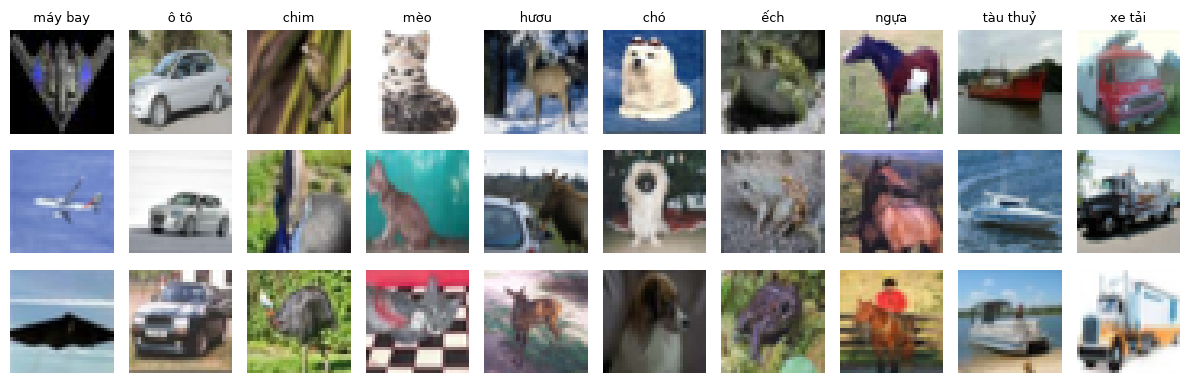

In [4]:
from huggingface_hub import hf_hub_download
pq = hf_hub_download("uoft-cs/cifar10", "plain_text/test-00000-of-00001.parquet", repo_type="dataset")
cifar = pd.read_parquet(pq)
targets = cifar["label"].to_numpy()
rng = np.random.default_rng(SEED)
idx = np.concatenate([rng.choice(np.where(targets == c)[0], N_PER_CLASS, replace=False) for c in range(10)])
images = [Image.open(io.BytesIO(cifar["img"].iloc[i]["bytes"])).convert("RGB") for i in idx]
labels = targets[idx]
print(len(images), "ảnh, mỗi lớp", np.bincount(labels)[0], "ảnh")

fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for c in range(10):
    for r in range(3):
        axes[r, c].imshow(images[c * N_PER_CLASS + r]); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=9)
plt.tight_layout(); plt.show()

### Nạp 3 mô hình
ViT được nạp với `attn_implementation='eager'` để lấy được bản đồ attention ở phần 4.

In [5]:
from diffusers import AutoencoderKL
from transformers import ViTModel, AutoModel

vae   = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(DEVICE).eval()    # fp32 cho ổn định
vit   = ViTModel.from_pretrained("google/vit-base-patch16-224", add_pooling_layer=False, dtype=DTYPE,
                                 attn_implementation="eager").to(DEVICE).eval()
vjepa = AutoModel.from_pretrained("facebook/vjepa2-vitl-fpc64-256", dtype=DTYPE).to(DEVICE).eval()
for n, m in [("VAE", vae), ("ViT", vit), ("V-JEPA", vjepa)]:
    print(f"{n:7s}: {sum(p.numel() for p in m.parameters())/1e6:.0f} triệu tham số")

VAE    : 84 triệu tham số
ViT    : 86 triệu tham số
V-JEPA : 326 triệu tham số


### Hàm trích embedding (phần chính của bài)
Mỗi mô hình có cách tiền xử lý riêng: VAE cần ảnh 256×256 trong khoảng [-1, 1], ViT cần 224×224 chuẩn hoá (x-0.5)/0.5, V-JEPA cần video 256×256 chuẩn hoá theo mean/std của ImageNet.

In [6]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3, 1, 1)

@torch.no_grad()
def S_vae(x):          # x: (B,3,256,256) trong [0,1]
    return vae.encode((x * 2 - 1).to(DEVICE)).latent_dist.mean.flatten(1).float().cpu()     # 4096 số

@torch.no_grad()
def S_vit(x):          # x: (B,3,224,224) trong [0,1]
    return vit(pixel_values=((x - 0.5) / 0.5).to(DEVICE, DTYPE)).last_hidden_state[:, 0].float().cpu()   # [CLS], 768 số

@torch.no_grad()
def S_vjepa(clip):     # clip: (B,T,3,256,256) trong [0,1]
    h = vjepa.get_vision_features(pixel_values_videos=((clip - MEAN) / STD).to(DEVICE, DTYPE))
    return h.mean(1).float().cpu()                                                            # 1024 số

def embed_images(imgs, model, bs=32):
    out = []
    for i in range(0, len(imgs), bs):
        b = imgs[i:i + bs]
        if model == "VAE": out.append(S_vae(pil_to_tensor(b, 256)))
        if model == "ViT": out.append(S_vit(pil_to_tensor(b, 224)))
        if model == "V-JEPA":
            clip = pil_to_tensor(b, 256).unsqueeze(1).repeat(1, 16, 1, 1, 1)                 # ảnh -> video đứng yên
            out.append(torch.cat([S_vjepa(clip[j:j + 8]) for j in range(0, len(clip), 8)]))
    return torch.cat(out).numpy()

S = cached("embeddings_images", lambda: {m: embed_images(images, m) for m in MODELS})
S["Pixel"] = np.stack([np.asarray(im, dtype=np.float32).ravel() / 255 for im in images])     # 3072 số
pd.DataFrame({m: [S[m].shape[1]] for m in ALL}, index=["số chiều của S"])

,Pixel,VAE,ViT,V-JEPA
số chiều của S,3072,4096,768,1024


Thử xem embedding của một ảnh trông như thế nào:

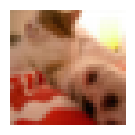

S_VAE     (4096 số): [+7.55, +6.44, +7.19, +7.34, +7.41, +9.02, ...]


S_ViT     ( 768 số): [+0.07, -0.06, +0.20, +0.02, +0.14, -1.82, ...]


S_V-JEPA  (1024 số): [-0.24, -0.83, -0.83, -1.99, -3.38, +0.17, ...]


In [7]:
img = images[3 * N_PER_CLASS + 5]
plt.figure(figsize=(1.5, 1.5)); plt.imshow(img); plt.axis("off"); plt.show()
for m in MODELS:
    s = embed_images([img], m)[0]
    print(f"S_{m:7s} ({s.size:4d} số): [{', '.join(f'{v:+.2f}' for v in s[:6])}, ...]")

## 3. So sánh 1 – Hình dạng không gian embedding

Phần này em xem hình dạng không gian embedding của 3 mô hình: VAE dạng cầu mịn, ViT và V-JEPA chia cụm như thế nào.

### 3.1 Chiếu xuống 2D bằng PCA, t-SNE, UMAP
PCA là chiếu tuyến tính (giữ cấu trúc tổng thể). t-SNE và UMAP là phi tuyến (giữ các điểm gần nhau). Mỗi chấm là 1 ảnh, màu là lớp thật.

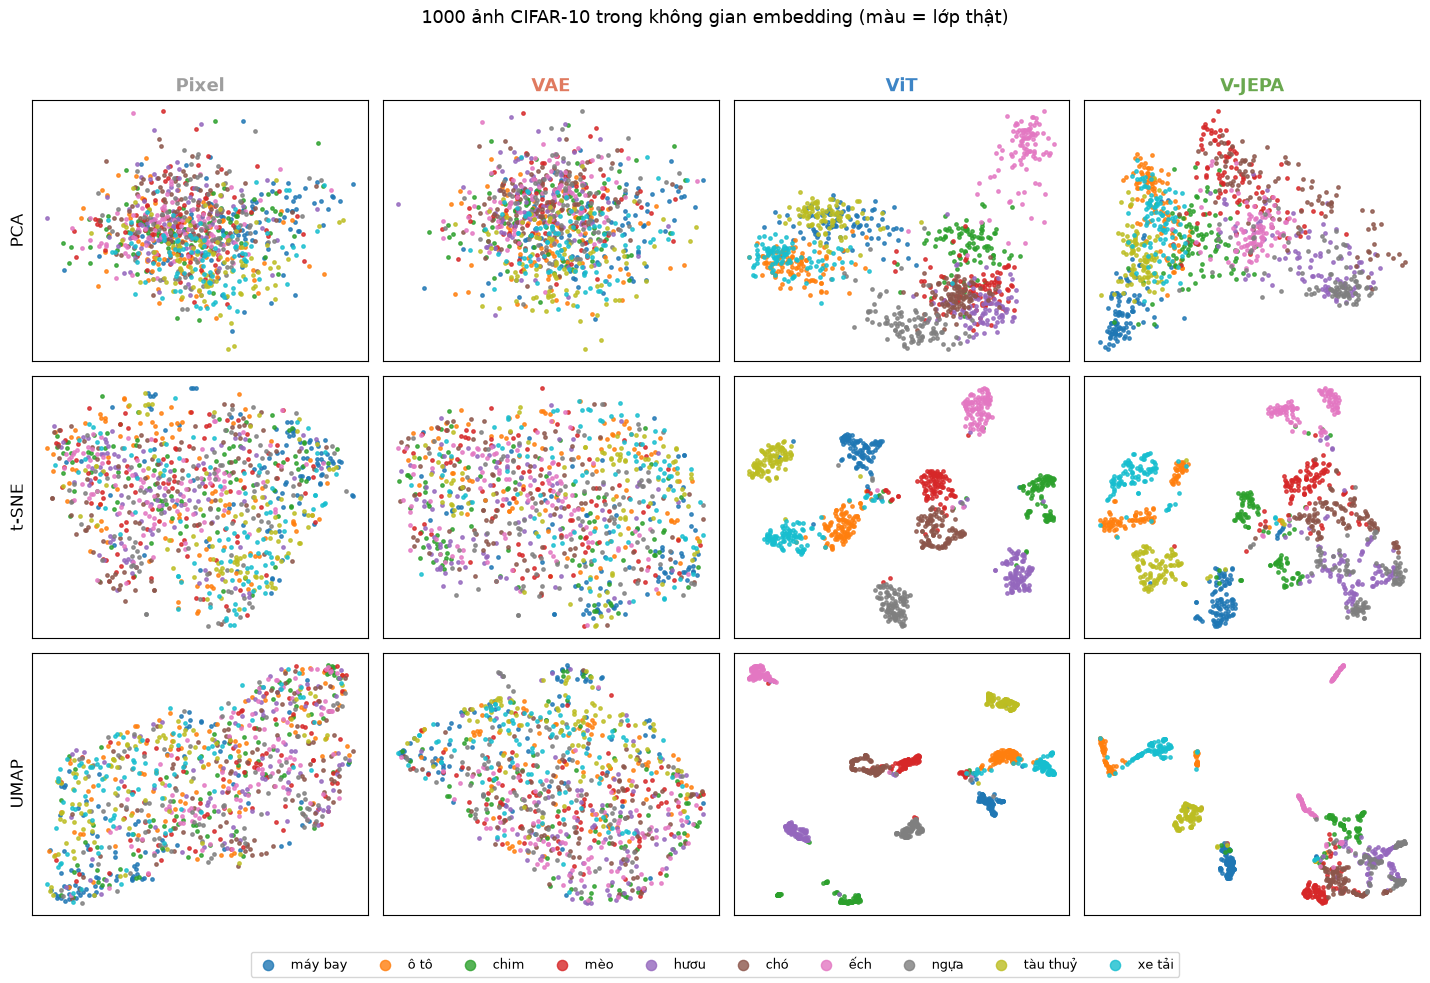

In [8]:
scatter_grid(S, labels, CLASSES, ALL, ["PCA", "t-SNE", "UMAP"], "1000 ảnh CIFAR-10 trong không gian embedding (màu = lớp thật)")

Nhận xét:
- Pixel và VAE nhìn gần như giống nhau: các màu trộn lẫn thành một đám, không chia lớp.
- ViT tách thành 10 cụm rõ, kể cả với PCA.
- V-JEPA cũng tách cụm dù không học bằng nhãn. Có lớp bị tách ra thành 2 cụm nhỏ (ví dụ ếch, ô tô trên t-SNE), nhóm động vật thì chồng lấn hơn ViT. Trên PCA thấy V-JEPA chia khá rõ phương tiện một bên, động vật một bên.

### 3.2 Nhìn trong 3D và bản đồ mật độ
Em chiếu PCA xuống 3 chiều, chuẩn hoá 3 trục về cùng thang, rồi vẽ thêm một mặt cầu (lưới xám) để dễ so sánh hình dạng. Bên dưới là bản đồ mật độ: chỗ sáng là chỗ có nhiều ảnh.

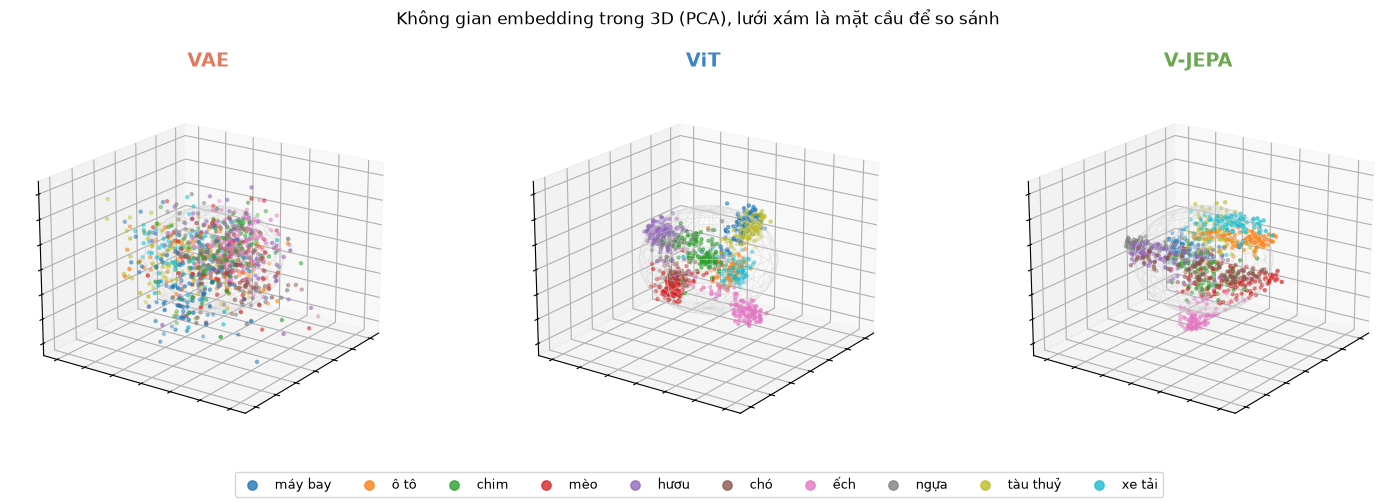

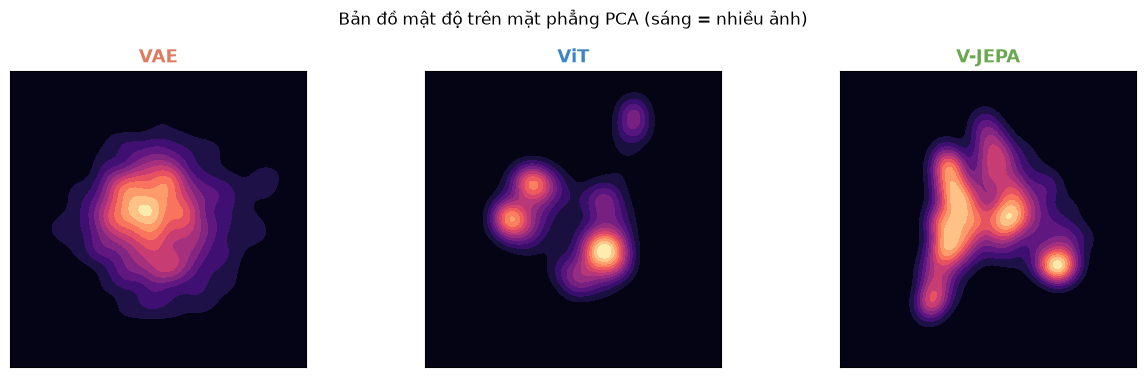

In [9]:
def plot_space_3d(models=MODELS):
    fig = plt.figure(figsize=(5 * len(models), 5))
    u, v = np.mgrid[0:2 * np.pi:30j, 0:np.pi:15j]
    for i, m in enumerate(models):
        Z = PCA(3, random_state=SEED).fit_transform(StandardScaler().fit_transform(S[m])); Z = Z / Z.std(0)
        ax = fig.add_subplot(1, len(models), i + 1, projection="3d")
        ax.plot_wireframe(2 * np.cos(u) * np.sin(v), 2 * np.sin(u) * np.sin(v), 2 * np.cos(v), color="lightgray", lw=0.4, alpha=0.6)
        for c in range(10):
            s = labels == c
            ax.scatter(Z[s, 0], Z[s, 1], Z[s, 2], s=5, color=CMAP(c), label=CLASSES[c], alpha=0.8)
        ax.set_title(m, color=COLORS[m], fontsize=14, fontweight="bold")
        for f in (ax.set_xlim, ax.set_ylim, ax.set_zlim): f(-3.5, 3.5)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([]); ax.view_init(elev=20, azim=35)
    fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=10, markerscale=3, fontsize=9)
    plt.suptitle("Không gian embedding trong 3D (PCA), lưới xám là mặt cầu để so sánh"); plt.tight_layout(rect=(0, 0.06, 1, 0.95)); plt.show()

def plot_density(models=MODELS):
    from scipy.stats import gaussian_kde
    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.8))
    for ax, m in zip(axes, models):
        Z = PCA(2, random_state=SEED).fit_transform(StandardScaler().fit_transform(S[m])); Z = Z / Z.std(0)
        xx, yy = np.mgrid[-3.5:3.5:150j, -3.5:3.5:150j]
        dens = gaussian_kde(Z.T, bw_method=0.25)(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
        ax.contourf(xx, yy, dens, levels=14, cmap="magma"); ax.set_aspect("equal")
        ax.set_title(m, color=COLORS[m], fontsize=13, fontweight="bold"); ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle("Bản đồ mật độ trên mặt phẳng PCA (sáng = nhiều ảnh)"); plt.tight_layout(); plt.show()

plot_space_3d(); plot_density()

Nhận xét:
- VAE: các điểm tạo thành một khối tròn liền, nằm gọn trong mặt cầu. Mật độ chỉ có một đỉnh ở giữa rồi thưa dần ra ngoài. Đây là dạng cầu mịn giống lý thuyết, do ràng buộc KL kéo latent về phân phối chuẩn N(0, I) nên không gian liền mạch, không có khoảng trống giữa các nhóm.
- ViT: các điểm tách thành các khối riêng nằm ở các hướng khác nhau, bản đồ mật độ có 3–4 đỉnh tách biệt.
- V-JEPA: cũng có nhiều cụm nhưng các cụm nối với nhau, mật độ có nhiều đỉnh nhỏ hơn.

### 3.3 Số cụm tự nhiên của mỗi không gian
Để kiểm tra việc V-JEPA chia nhiều cụm bằng số, em chạy KMeans (không dùng nhãn) với nhiều số cụm k khác nhau và đo silhouette. Silhouette cao nghĩa là chia thành k cụm đó hợp lý. Nếu đường cong không có đỉnh thì không gian không có cụm tự nhiên.

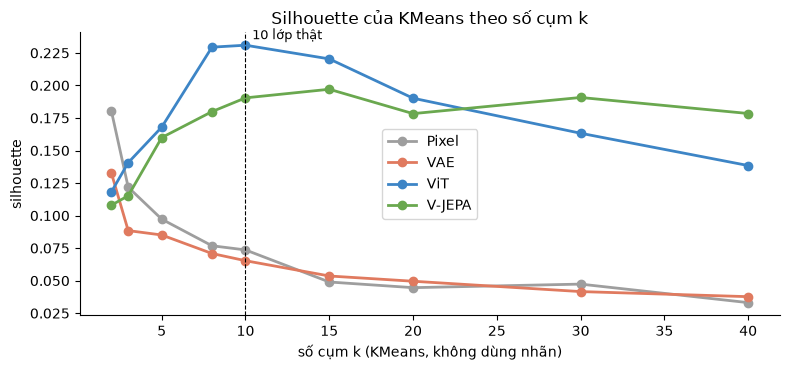

,k=2,k=3,k=5,k=8,k=10,k=15,k=20,k=30,k=40
Pixel,0.180,0.122,0.097,0.077,0.074,0.049,0.045,0.047,0.033
VAE,0.133,0.088,0.085,0.071,0.065,0.054,0.050,0.042,0.038
ViT,0.118,0.141,0.168,0.229,0.231,0.220,0.190,0.163,0.138
V-JEPA,0.108,0.115,0.160,0.180,0.190,0.197,0.178,0.191,0.178


In [10]:
KS = [2, 3, 5, 8, 10, 15, 20, 30, 40]
def kmeans_curve():
    out = {}
    for m in ALL:
        X = PCA(50, random_state=SEED).fit_transform(StandardScaler().fit_transform(S[m]))
        out[m] = np.array([silhouette_score(X, KMeans(k, n_init=5, random_state=SEED).fit_predict(X)) for k in KS])
    return out
kc = cached("kmeans_curve", kmeans_curve)

fig, ax = plt.subplots(figsize=(8, 3.8))
for m in ALL: ax.plot(KS, kc[m], "o-", color=COLORS[m], lw=2, label=m)
ax.axvline(10, ls="--", c="k", lw=0.8); ax.text(10.4, max(kc["ViT"]) * 1.02, "10 lớp thật", fontsize=9)
ax.set_xlabel("số cụm k (KMeans, không dùng nhãn)"); ax.set_ylabel("silhouette"); ax.legend()
ax.set_title("Silhouette của KMeans theo số cụm k"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
pd.DataFrame(kc, index=[f"k={k}" for k in KS]).T.round(3)

Nhận xét:
- Pixel và VAE: silhouette cao nhất ở k=2 rồi giảm đều khi tăng k, không có đỉnh nào. Nghĩa là không gian VAE không tự chia cụm, nó là một khối liền (khớp với hình cầu ở trên).
- ViT: có đỉnh rõ ở khoảng k=8–10, đúng bằng số lớp. ViT chia đúng theo nhãn nó đã học.
- V-JEPA: silhouette tăng tới k=10 rồi vẫn giữ cao tới k=30, không giảm như ViT. Vậy V-JEPA chia không gian thành nhiều cụm nhỏ hơn số lớp. Em nghĩ là do V-JEPA không học theo 10 nhãn nên nó tự nhóm theo các đặc điểm chi tiết hơn (góc nhìn, dáng, bối cảnh) bên trong mỗi lớp.

### 3.4 Kiểm tra độ mịn của không gian VAE
Em làm hai kiểm tra:
1. Giải mã ngược: lấy embedding của VAE cho qua decoder để vẽ lại ảnh. Nếu vẽ lại giống thì embedding giữ gần đủ thông tin pixel.
2. Nội suy: đi trên đường thẳng giữa 2 điểm trong không gian VAE (máy bay sang tàu thuỷ), giải mã từng điểm. Không gian mịn thì ảnh biến đổi từ từ, điểm ở giữa vẫn ra ảnh bình thường. ViT và V-JEPA không có decoder nên không làm được việc này.

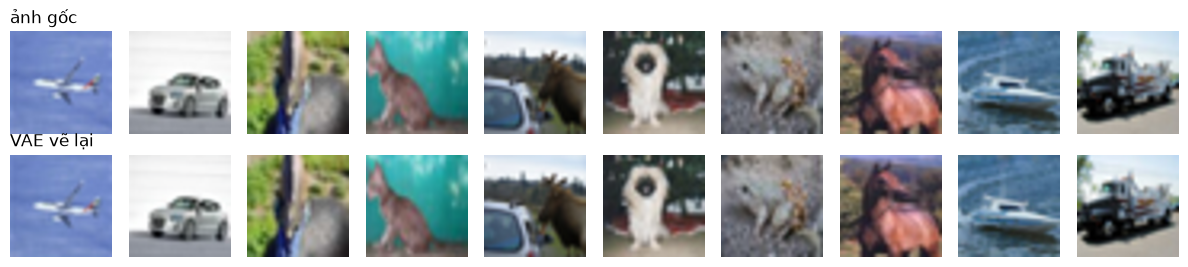

PSNR = 45.4 dB


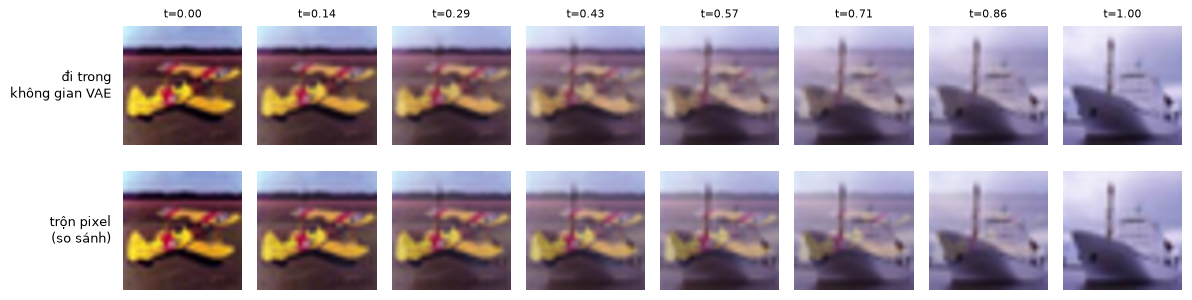

In [11]:
demo = [images[c * N_PER_CLASS + 1] for c in range(10)]
with torch.no_grad():
    x = pil_to_tensor(demo, 256).to(DEVICE)
    rec = ((vae.decode(vae.encode(x * 2 - 1).latent_dist.mean).sample.clamp(-1, 1) + 1) / 2).cpu()
fig, axes = plt.subplots(2, 10, figsize=(12, 2.7))
for j in range(10):
    axes[0, j].imshow(x[j].permute(1, 2, 0).cpu()); axes[1, j].imshow(rec[j].permute(1, 2, 0))
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].set_title("ảnh gốc", loc="left"); axes[1, 0].set_title("VAE vẽ lại", loc="left"); plt.tight_layout(); plt.show()
mse = torch.mean((rec - x.cpu()) ** 2).item(); print(f"PSNR = {10*np.log10(1/mse):.1f} dB")

steps = 8; ts = np.linspace(0, 1, steps)
with torch.no_grad():
    xa = pil_to_tensor([images[3], images[8 * N_PER_CLASS + 3]], 256).to(DEVICE) * 2 - 1
    za, zb = vae.encode(xa).latent_dist.mean
    out = ((vae.decode(torch.stack([(1 - t) * za + t * zb for t in ts])).sample.clamp(-1, 1) + 1) / 2).cpu()
    mix = ((torch.stack([(1 - t) * xa[0] + t * xa[1] for t in ts]) + 1) / 2).cpu()
fig, axes = plt.subplots(2, steps, figsize=(1.5 * steps, 3.3))
for j in range(steps):
    axes[0, j].imshow(out[j].permute(1, 2, 0)); axes[1, j].imshow(mix[j].permute(1, 2, 0))
    axes[0, j].axis("off"); axes[1, j].axis("off"); axes[0, j].set_title(f"t={ts[j]:.2f}", fontsize=8)
axes[0, 0].text(-0.1, 0.5, "đi trong\nkhông gian VAE", transform=axes[0, 0].transAxes, ha="right", va="center", fontsize=9)
axes[1, 0].text(-0.1, 0.5, "trộn pixel\n(so sánh)", transform=axes[1, 0].transAxes, ha="right", va="center", fontsize=9)
plt.tight_layout(); plt.show()

Nhận xét: VAE vẽ lại gần như y hệt ảnh gốc (PSNR khoảng 45 dB). Khi đi từ máy bay sang tàu thuỷ trong không gian VAE, ảnh đổi dần dần, không có bước nào bị vỡ, nên không gian liền mạch. Tuy nhiên kết quả khá giống với trộn pixel ở hàng dưới, cho thấy không gian VAE này rất gần với không gian pixel (VAE của Stable Diffusion giữ cả bố cục không gian 32×32).

## 4. So sánh 2 – Biểu diễn không gian bên trong ảnh

Cả 3 mô hình bên trong đều chia ảnh thành lưới: VAE lưới 32×32, ViT lưới 14×14 patch, V-JEPA lưới 16×16. Em lấy vector của từng ô trong lưới, dùng PCA rút còn 3 thành phần rồi tô thành 3 màu R, G, B. Hai ô có màu giống nhau thì mô hình coi hai vùng đó giống nhau. Riêng ViT em vẽ thêm attention của token [CLS] ở lớp cuối để xem khi tóm tắt cả ảnh thì ViT chú ý vào vùng nào.

Ảnh CIFAR chỉ 32×32 nên quá nhỏ để xem, em dùng frame giữa của 4 video UCF101 (dữ liệu video ở phần 9).

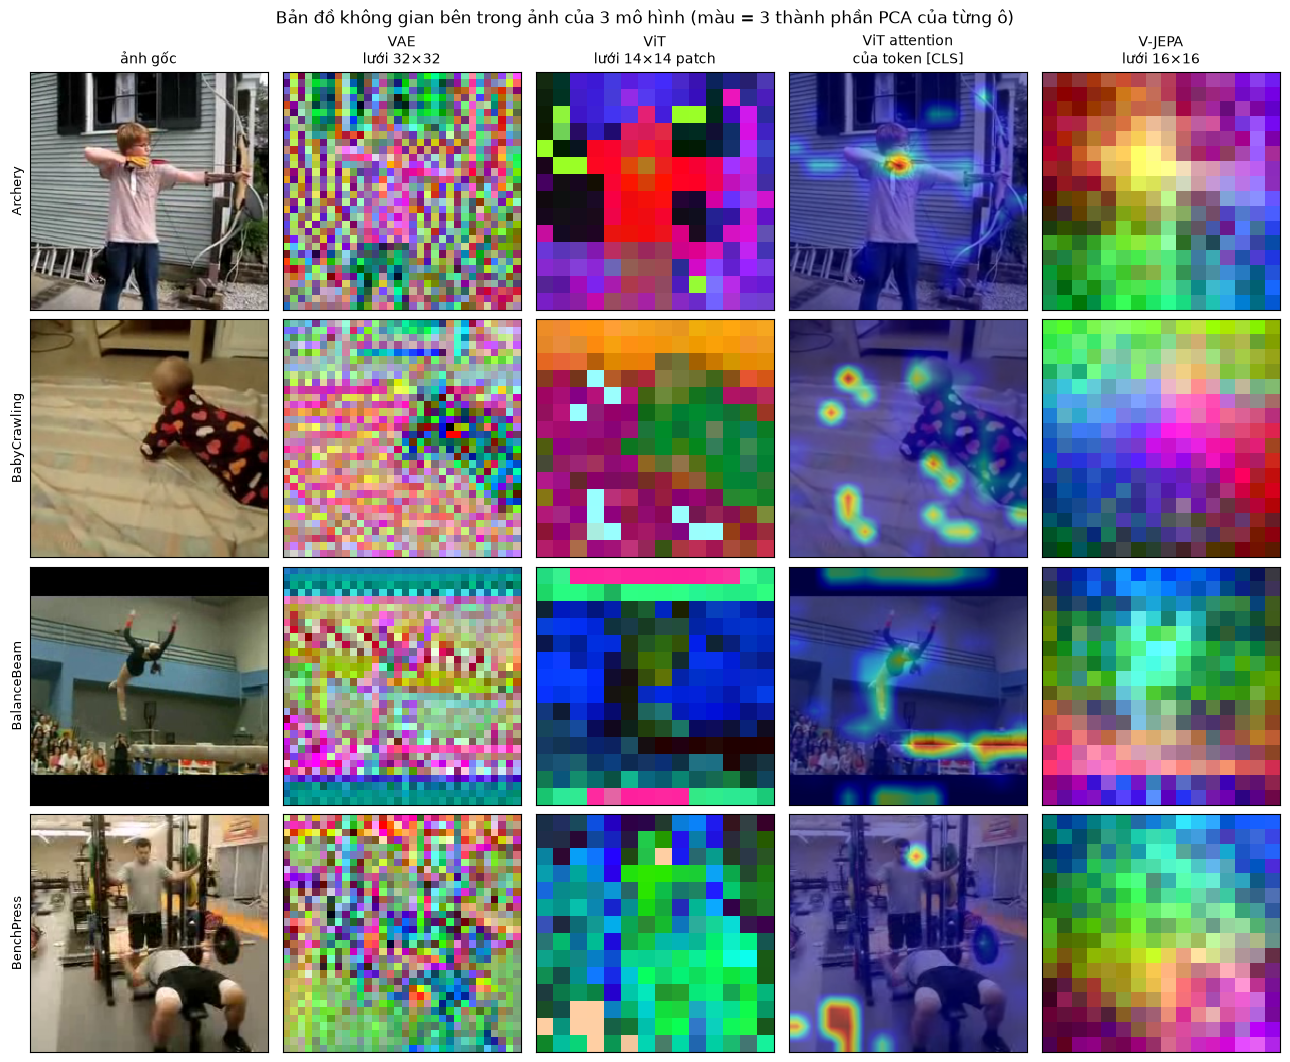

In [12]:
VID_DIR = DATA_DIR / "UCF101_subset"
if not VID_DIR.exists():
    tar_path = hf_hub_download("sayakpaul/ucf101-subset", "UCF101_subset.tar.gz", repo_type="dataset")
    with tarfile.open(tar_path) as t: t.extractall(DATA_DIR)
videos = sorted(VID_DIR.rglob("*.avi"))
VCLASSES = sorted({p.parent.name for p in videos})

def read_clip(path, n=16):
    import av
    with av.open(str(path)) as c:
        frames = [f.to_ndarray(format="rgb24") for f in c.decode(video=0)]
    ids = np.linspace(0, len(frames) - 1, n).round().astype(int)
    return np.stack([frames[i] for i in ids])

def pca_rgb(f):
    # f: (H, W, D) -> ảnh màu (H, W, 3); bỏ qua vài ô có độ lớn bất thường (hiện tượng đã biết ở ViT)
    X = f.reshape(-1, f.shape[-1]).astype(np.float64)
    ok = np.linalg.norm(X, axis=1) < np.percentile(np.linalg.norm(X, axis=1), 97)
    mu = X[ok].mean(0); z = PCA(3, random_state=SEED).fit(X[ok] - mu).transform(X - mu)
    lo, hi = np.percentile(z[ok], [2, 98], axis=0)
    return np.clip((z - lo) / (hi - lo), 0, 1).reshape(*f.shape[:2], 3)

@torch.no_grad()
def spatial_maps(frames):
    x256 = torch.stack([clip_to_tensor(f[None], 256)[0] for f in frames])
    x224 = torch.stack([clip_to_tensor(f[None], 224)[0] for f in frames])
    lat = vae.encode((x256 * 2 - 1).to(DEVICE)).latent_dist.mean.permute(0, 2, 3, 1).float().cpu().numpy()   # (N,32,32,4)
    o = vit(pixel_values=((x224 - 0.5) / 0.5).to(DEVICE, DTYPE), output_attentions=True)
    vit_tok = o.last_hidden_state[:, 1:].float().cpu().numpy().reshape(-1, 14, 14, 768)                        # 196 patch
    att = o.attentions[-1][:, :, 0, 1:].mean(1).float().cpu().numpy().reshape(-1, 14, 14)                       # [CLS] -> patch
    clip = x256.unsqueeze(1).repeat(1, 16, 1, 1, 1)
    h = vjepa.get_vision_features(pixel_values_videos=((clip - MEAN) / STD).to(DEVICE, DTYPE))
    vj_tok = h.float().cpu().numpy().reshape(-1, 8, 16, 16, 1024).mean(1)                                       # (N,16,16,1024)
    return x224, lat, vit_tok, att, vj_tok

pick = [VCLASSES.index(c) for c in ["Archery", "BabyCrawling", "BalanceBeam", "BenchPress"]]
frames = [read_clip([p for p in videos if p.parent.name == VCLASSES[c]][0])[8] for c in pick]
x224, lat, vit_tok, att, vj_tok = spatial_maps(frames)

cols = ["ảnh gốc", "VAE\nlưới 32×32", "ViT\nlưới 14×14 patch", "ViT attention\ncủa token [CLS]", "V-JEPA\nlưới 16×16"]
fig, axes = plt.subplots(len(frames), 5, figsize=(13, 2.7 * len(frames)))
for i in range(len(frames)):
    img = x224[i].permute(1, 2, 0).numpy().clip(0, 1)
    a = F.interpolate(torch.tensor(att[i] / att[i].max())[None, None], size=224, mode="bilinear")[0, 0].numpy()
    for j, p in enumerate([img, pca_rgb(lat[i]), pca_rgb(vit_tok[i]), None, pca_rgb(vj_tok[i])]):
        ax = axes[i, j]
        if j == 3: ax.imshow(img); ax.imshow(a, cmap="jet", alpha=0.5)
        else: ax.imshow(p, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(cols[j], fontsize=10)
    axes[i, 0].set_ylabel(VCLASSES[pick[i]], fontsize=9)
plt.suptitle("Bản đồ không gian bên trong ảnh của 3 mô hình (màu = 3 thành phần PCA của từng ô)"); plt.tight_layout(); plt.show()

Nhận xét:
- VAE: bản đồ lấm tấm như nhiễu, các ô cạnh nhau màu khác nhau, chỉ thấy lờ mờ đường viền (dáng người tập xà, em bé). VAE mã hoá chi tiết từng vùng nhỏ (màu, kết cấu) chứ không gom các vùng cùng vật thể lại với nhau.
- ViT: bản đồ chia thành từng mảng lớn theo vật thể, người bắn cung một màu, nền một màu, bãi cỏ một màu. Attention của [CLS] tập trung vào vật thể quan trọng (cây cung, em bé, người tập tạ, xà thăng bằng). Mỗi patch của ViT mang thông tin nó thuộc vật thể nào, còn [CLS] gom thông tin từ các patch quan trọng.
- V-JEPA: bản đồ mượt, chuyển màu từ từ, vùng vật thể chính nổi lên ở giữa (ví dụ người tập tạ). Ranh giới không rõ như ViT, em nghĩ là vì V-JEPA được train để đoán vùng bị che từ vùng xung quanh nên mỗi token mang cả thông tin của vùng lân cận.

### 4.1 Không gian các ô trong một ảnh và chỉ số RankMe

Ở phần 3 mỗi điểm là một bức ảnh. Ở đây em vẽ theo cách khác: mỗi điểm là một ô trong cùng một bức ảnh. Các bước:
1. Lấy vector của từng ô (VAE: 1024 ô, mỗi ô 4 chiều; ViT: 196 ô, 768 chiều; V-JEPA: 256 ô, 1024 chiều).
2. Chuẩn hoá mỗi vector về độ dài 1, khi đó mọi điểm nằm trên mặt một quả cầu.
3. Chiếu PCA xuống 2D.
4. Chọn ô A trên người (dấu X đen) và ô B trên nền (dấu X xanh), tô màu mỗi ô theo độ giống cosine với A (đỏ) so với B (xanh).

RankMe (Garrido và cộng sự, 2023) đo số chiều mà biểu diễn thực sự sử dụng, tính bằng exp của entropy các giá trị suy biến đã chuẩn hoá. Số càng lớn thì biểu diễn dùng càng nhiều chiều.

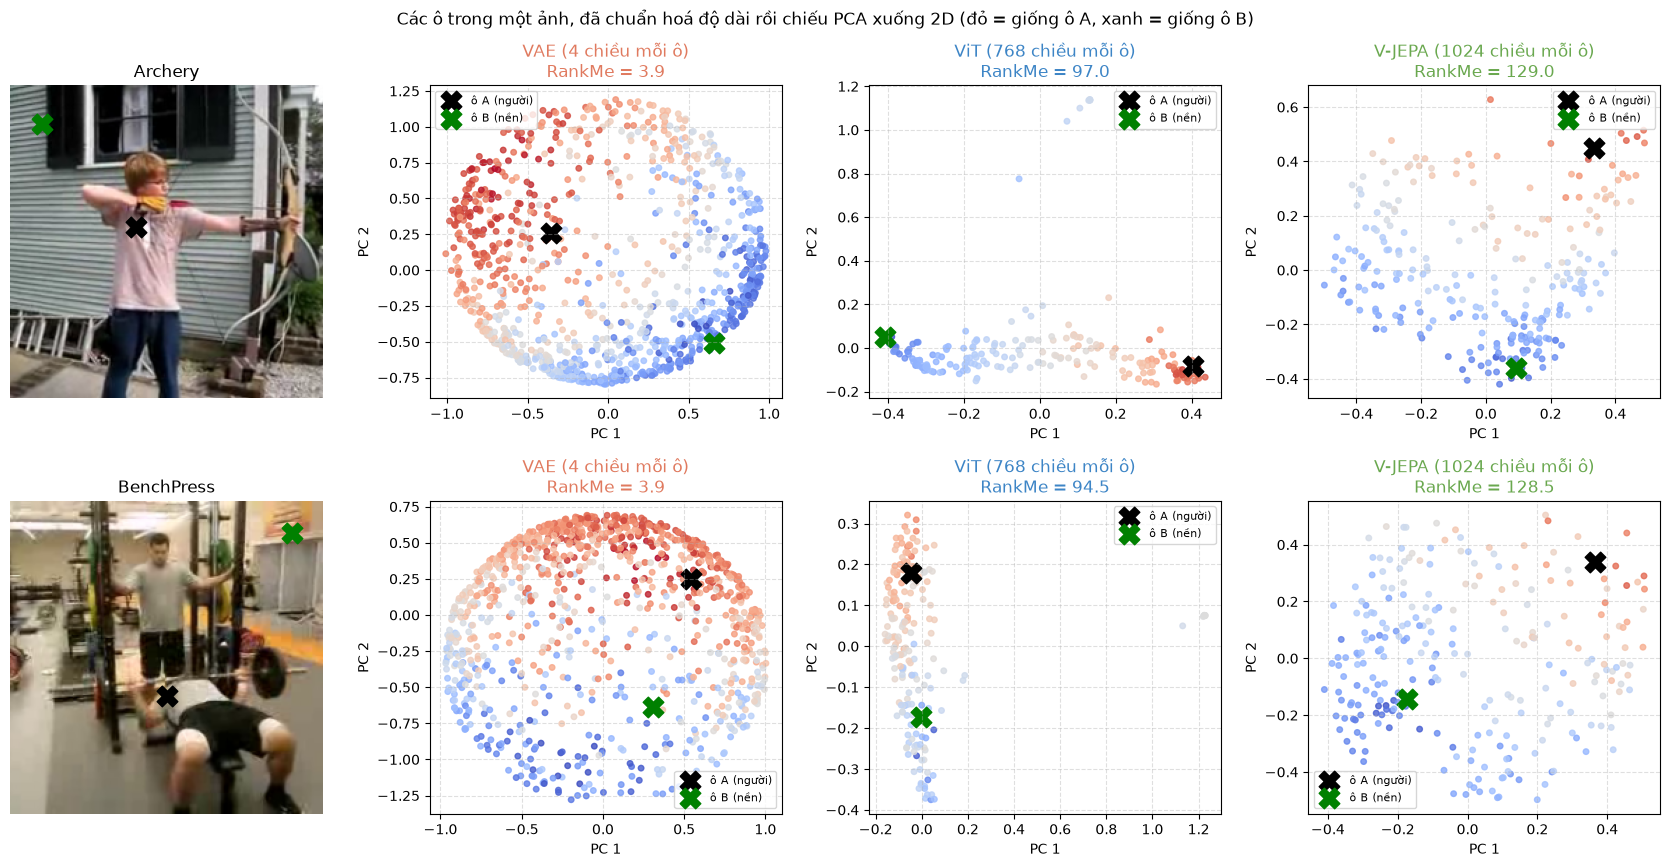

,VAE,ViT,V-JEPA
Archery,3.9,97.0,129.0
BenchPress,3.9,94.5,128.5


In [13]:
def rankme(X):
    s = np.linalg.svd(X, compute_uv=False); p = s / s.sum() + 1e-7
    return float(np.exp(-(p * np.log(p)).sum()))

# vị trí tương đối (hàng, cột) của ô A (người) và ô B (nền) cho 2 ảnh Archery và BenchPress
QUERIES = {0: ((0.45, 0.40), (0.12, 0.10)), 3: ((0.62, 0.50), (0.10, 0.90))}
fig, axes = plt.subplots(len(QUERIES), 4, figsize=(17, 4.4 * len(QUERIES)))
rank_tab = {}
for r, (i, (qa, qb)) in enumerate(QUERIES.items()):
    img = x224[i].permute(1, 2, 0).numpy().clip(0, 1)
    axes[r, 0].imshow(img); axes[r, 0].axis("off"); axes[r, 0].set_title(VCLASSES[pick[i]])
    axes[r, 0].scatter([qa[1] * 224], [qa[0] * 224], marker="X", s=220, c="k")
    axes[r, 0].scatter([qb[1] * 224], [qb[0] * 224], marker="X", s=220, c="g")
    for ax, (m, f) in zip(axes[r, 1:], [("VAE", lat[i]), ("ViT", vit_tok[i]), ("V-JEPA", vj_tok[i])]):
        H, W, d = f.shape
        X = f.reshape(-1, d).astype(np.float64); X = X / np.linalg.norm(X, axis=1, keepdims=True)
        ia = int(qa[0] * H) * W + int(qa[1] * W); ib = int(qb[0] * H) * W + int(qb[1] * W)
        Z = PCA(2, random_state=SEED).fit_transform(X)
        ax.scatter(Z[:, 0], Z[:, 1], c=X @ X[ia] - X @ X[ib], cmap="coolwarm", s=16, alpha=0.8)
        ax.scatter(*Z[ia], marker="X", s=220, c="k", label="ô A (người)")
        ax.scatter(*Z[ib], marker="X", s=220, c="g", label="ô B (nền)")
        rank_tab.setdefault(m, {})[VCLASSES[pick[i]]] = rankme(X)
        ax.set_title(f"{m} ({d} chiều mỗi ô)\nRankMe = {rankme(X):.1f}", color=COLORS[m]); ax.grid(ls="--", alpha=0.4)
        ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=8)
plt.suptitle("Các ô trong một ảnh, đã chuẩn hoá độ dài rồi chiếu PCA xuống 2D (đỏ = giống ô A, xanh = giống ô B)")
plt.tight_layout(); plt.show()
pd.DataFrame(rank_tab).round(1)

Nhận xét:
- VAE: các điểm xếp thành vòng tròn, đúng dạng mặt cầu. Lý do là mỗi ô chỉ có 4 chiều và RankMe gần bằng 4, tức cả 4 chiều đều được dùng đều nhau, nên mặt cầu trong 4 chiều chiếu xuống 2D vẫn hiện rõ hình tròn. Các ô giống người và giống nền nằm ở hai phía của vòng tròn, nhưng chủ yếu khác nhau về màu sắc và độ sáng.
- ViT: RankMe khoảng 95, cao hơn rất nhiều. Các ô xếp thành một dải, ô thuộc người nằm ở một đầu, ô thuộc nền ở đầu kia, thêm vài ô bất thường nằm tách xa. Không còn hình tròn vì 2 chiều PCA chỉ là 2 trong rất nhiều hướng mà ViT sử dụng.
- V-JEPA: RankMe cao nhất, dùng nhiều chiều nhất. Các ô trải ra liên tục, ô giống người và ô giống nền nằm ở hai đầu nhưng chuyển tiếp từ từ, khớp với bản đồ mượt ở trên.
- Như vậy hình cầu của VAE xuất hiện vì biểu diễn mỗi ô rất ít chiều. ViT và V-JEPA có biểu diễn giàu chiều hơn nhiều nên không gian có cấu trúc cụm thay vì một mặt cầu đơn giản.

## 5. So sánh 3 – Đo bằng số: embedding chứa bao nhiêu thông tin ngữ nghĩa

Hình 2D có thể bị méo, nên em đo trực tiếp trên embedding gốc:
- Silhouette (cosine): ảnh cùng lớp có gần nhau hơn ảnh khác lớp không, từ -1 đến 1.
- k-NN accuracy: đoán lớp theo 10 ảnh gần nhất.
- Linear probe: giữ nguyên mô hình, chỉ train một bộ phân loại tuyến tính (Logistic Regression) trên embedding. Bộ phân loại này rất đơn giản, chỉ kẻ được đường thẳng, nên nếu đạt điểm cao thì là nhờ embedding đã sắp xếp các lớp gọn gàng sẵn.

Dùng 5-fold cross-validation. Có 10 lớp nên đoán bừa được khoảng 10%.

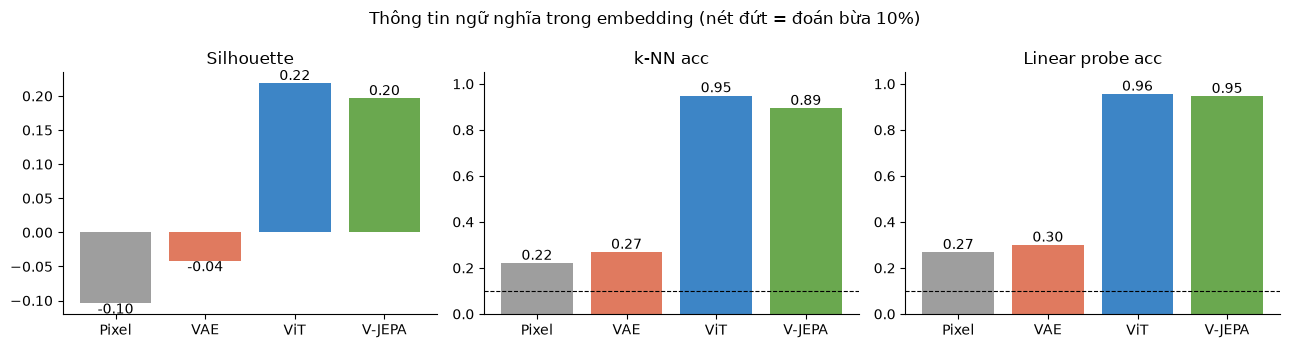

,Silhouette,k-NN acc,Linear probe acc
Pixel,-0.104,0.221,0.268
VAE,-0.041,0.269,0.300
ViT,0.219,0.949,0.956
V-JEPA,0.196,0.894,0.946


In [14]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
metrics = pd.DataFrame({m: evaluate(S[m], labels, cv) for m in ALL}).T

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, metrics.columns):
    bars = ax.bar(metrics.index, metrics[col], color=[COLORS[m] for m in metrics.index])
    ax.bar_label(bars, fmt="%.2f"); ax.set_title(col); ax.spines[["top", "right"]].set_visible(False)
    if "acc" in col: ax.axhline(0.1, ls="--", c="k", lw=0.8); ax.set_ylim(0, 1.05)
plt.suptitle("Thông tin ngữ nghĩa trong embedding (nét đứt = đoán bừa 10%)"); plt.tight_layout(); plt.show()
metrics.round(3)

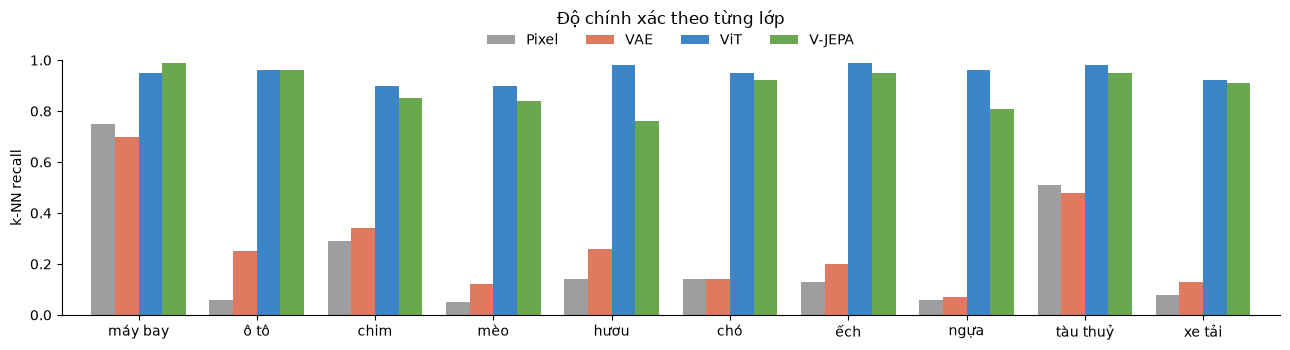

Số thành phần PCA cần để giữ 90% phương sai: {'Pixel': 84, 'VAE': 306, 'ViT': 256, 'V-JEPA': 57}


In [15]:
per_class = pd.DataFrame({m: recall_score(labels, cross_val_predict(KNeighborsClassifier(10, metric="cosine"), S[m], labels, cv=cv), average=None)
                          for m in ALL}, index=CLASSES)
ax = per_class.plot.bar(figsize=(13, 3.6), width=0.8, color=[COLORS[m] for m in ALL], rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("k-NN recall"); ax.set_title("Độ chính xác theo từng lớp", pad=26)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

dim90 = {}
for m in ALL:
    ev = np.cumsum(PCA(random_state=SEED).fit(StandardScaler().fit_transform(S[m])).explained_variance_ratio_)
    dim90[m] = int(np.searchsorted(ev, 0.9) + 1)
print("Số thành phần PCA cần để giữ 90% phương sai:", dim90)

Nhận xét:
- ViT cao nhất (linear probe khoảng 95–96%), V-JEPA sát sau (khoảng 94–95%), VAE chỉ khoảng 30%, gần bằng pixel thô (27%).
- V-JEPA không dùng nhãn mà chỉ thua ViT khoảng 1 điểm. VAE cũng không dùng nhãn nhưng thua xa. Em nghĩ khác biệt là do V-JEPA học đoán embedding, còn VAE học đoán pixel.
- Theo từng lớp: VAE chỉ nhận được máy bay và tàu thuỷ, là hai lớp có nền trời hoặc biển xanh, nên VAE chủ yếu dựa vào màu nền. V-JEPA kém ViT rõ nhất ở hươu và ngựa.
- V-JEPA cần ít thành phần PCA nhất để giữ 90% phương sai, biểu diễn gọn nhất. VAE cần nhiều nhất vì giữ nhiều chi tiết pixel.

## 6. So sánh 4 – Mức độ giống nhau giữa các mô hình (CKA)

CKA (Centered Kernel Alignment) so sánh 2 biểu diễn có số chiều khác nhau. Với mỗi biểu diễn, tính độ giống giữa mọi cặp ảnh (ma trận 1000×1000), rồi xem 2 ma trận này khớp nhau bao nhiêu. CKA gần 1 nghĩa là 2 mô hình xếp các ảnh gần/xa nhau theo cùng một cách.

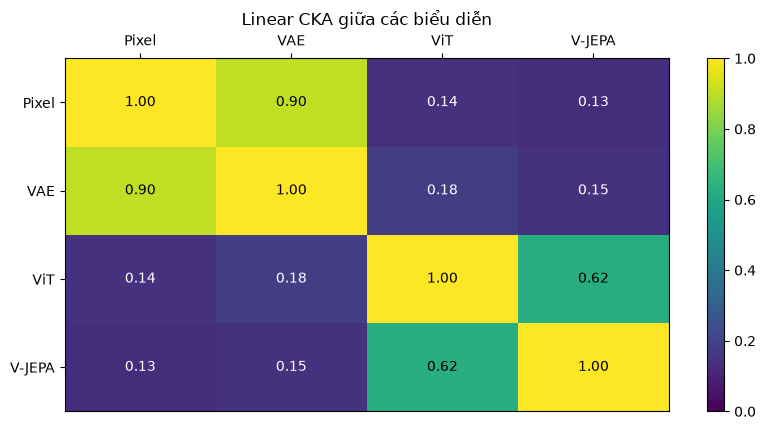

In [16]:
cka = pd.DataFrame([[linear_cka(S[a], S[b]) for b in ALL] for a in ALL], index=ALL, columns=ALL)
heatmap(cka, "Linear CKA giữa các biểu diễn")

Nhận xét: VAE và Pixel có CKA khoảng 0.90, VAE gần như là pixel được nén lại. ViT và V-JEPA khoảng 0.62, khá giống nhau vì cùng nắm ngữ nghĩa nhưng không trùng hoàn toàn. Giữa nhóm VAE/Pixel và nhóm ViT/V-JEPA chỉ khoảng 0.15, hai nhóm biểu diễn ảnh theo hai cách gần như không liên quan.

## 7. So sánh 5 – Tìm ảnh giống nhất

Với một ảnh truy vấn, mỗi mô hình tìm 5 ảnh có embedding gần nhất (cosine). Viền xanh là cùng lớp, viền đỏ là khác lớp.

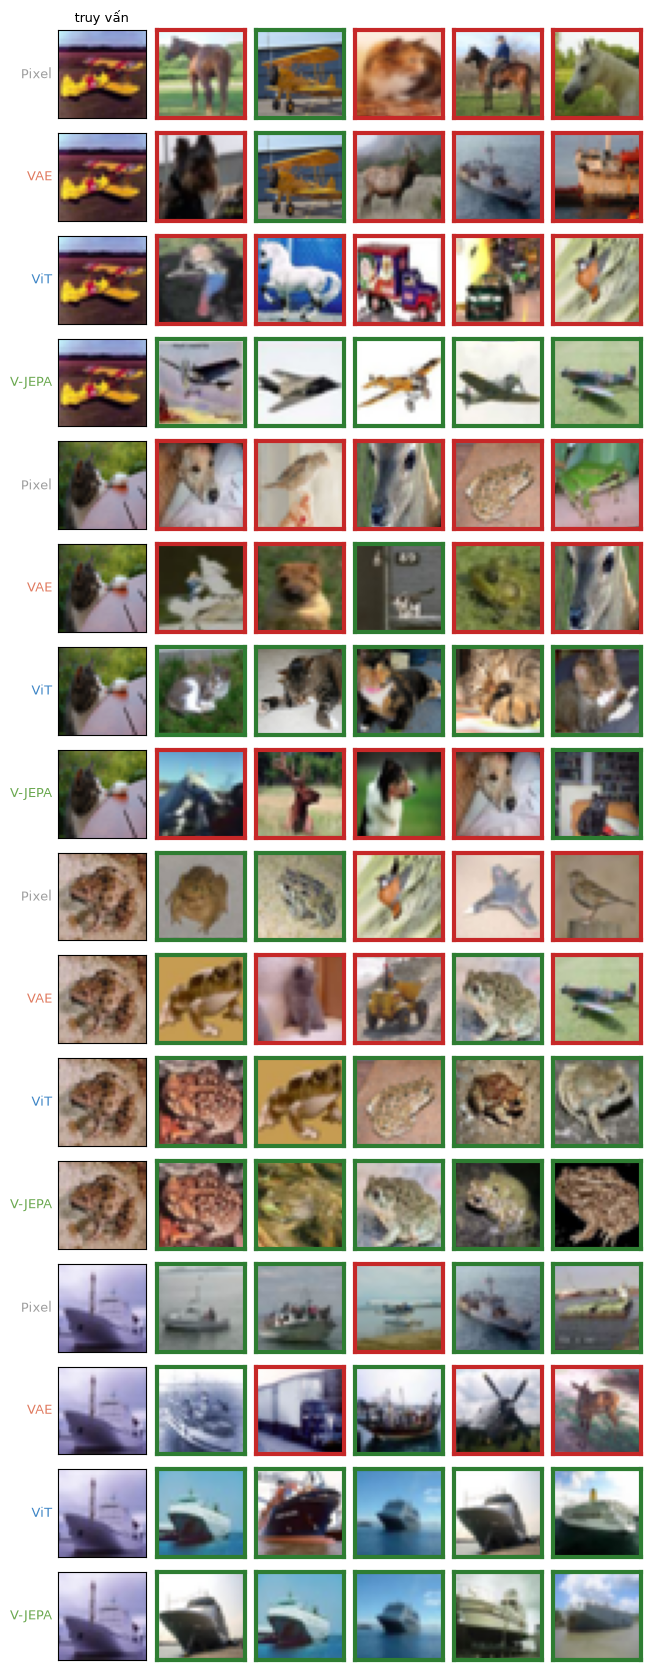

In [17]:
def show_retrieval(queries, k=5):
    fig, axes = plt.subplots(len(queries) * len(ALL), k + 1, figsize=(k + 1.6, len(queries) * len(ALL) * 1.05))
    for qi, q in enumerate(queries):
        for mi, m in enumerate(ALL):
            r = qi * len(ALL) + mi
            X = S[m] / np.linalg.norm(S[m], axis=1, keepdims=True); sims = X @ X[q]; sims[q] = -np.inf
            axes[r, 0].imshow(images[q])
            axes[r, 0].set_ylabel(m, rotation=0, ha="right", va="center", fontsize=9, color=COLORS[m])
            for j, n in enumerate(np.argsort(-sims)[:k]):
                axes[r, j + 1].imshow(images[n])
                for sp in axes[r, j + 1].spines.values():
                    sp.set_color("#2e7d32" if labels[n] == labels[q] else "#c62828"); sp.set_linewidth(3)
            for ax in axes[r]: ax.set_xticks([]); ax.set_yticks([])
    axes[0, 0].set_title("truy vấn", fontsize=9); plt.tight_layout(); plt.show()

show_retrieval([0 * N_PER_CLASS + 3, 3 * N_PER_CLASS + 3, 6 * N_PER_CLASS + 3, 8 * N_PER_CLASS + 3])

Nhận xét: Pixel và VAE trả về ảnh cùng tông màu, cùng bố cục (ảnh tàu thuỷ nền tím trả về xe tải, trực thăng cũng tông tím). ViT và V-JEPA trả về ảnh cùng loại vật thể dù màu và góc chụp khác. Với ảnh máy bay đồ chơi, ViT trả về các đồ chơi khác (xe tải đồ chơi, ngựa gỗ), còn V-JEPA trả về đủ 5 máy bay. Ngược lại với ảnh con mèo, ViT đúng 5/5 còn V-JEPA nhầm sang chó, hươu.

## 8. So sánh 6 – Tính bất biến khi biến đổi ảnh

Biến đổi 300 ảnh (chuyển xám, lật ngang, cắt giữa, đảo màu) nhưng nội dung vẫn giữ nguyên, rồi đo embedding thay đổi bao nhiêu.

Mỗi mô hình có mức giống nền khác nhau (ví dụ với V-JEPA, hai ảnh bất kỳ đã có cosine khá cao), nên em chuẩn hoá: `(cos(gốc, biến đổi) - cos trung bình giữa 2 ảnh ngẫu nhiên) / (1 - cos ngẫu nhiên)`. Khi đó 1 là embedding không đổi, 0 là ảnh biến đổi bị coi như một ảnh khác hẳn.

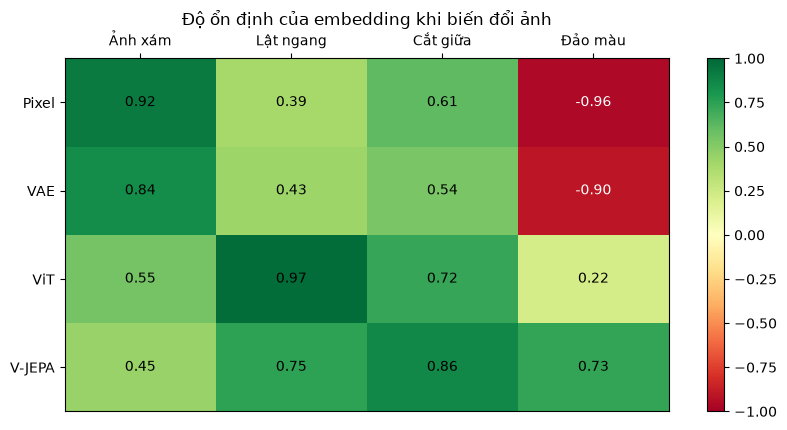

In [18]:
AUGS = {"Ảnh xám":   lambda im: im.convert("L").convert("RGB"),
        "Lật ngang": lambda im: im.transpose(Image.FLIP_LEFT_RIGHT),
        "Cắt giữa":  lambda im: im.crop((4, 4, 28, 28)).resize((32, 32), Image.BICUBIC),
        "Đảo màu":   lambda im: Image.eval(im, lambda p: 255 - p)}
sub = [images[i] for i in np.random.default_rng(SEED).choice(len(images), 300, replace=False)]
pix = lambda ims: np.stack([np.asarray(im, dtype=np.float32).ravel() / 255 for im in ims])
emb = lambda ims, m: pix(ims) if m == "Pixel" else embed_images(ims, m)

def invariance():
    res = {}
    for m in ALL:
        base = emb(sub, m)
        res[m] = np.array([stability(base, emb([f(im) for im in sub], m)) for f in AUGS.values()])
    return res
inv = pd.DataFrame(cached("invariance", invariance), index=list(AUGS)).T
heatmap(inv, "Độ ổn định của embedding khi biến đổi ảnh", cmap="RdYlGn", vmin=-1, vmax=1)

Nhận xét:
- Đảo màu: Pixel và VAE ra số âm (khoảng -0.9), tức embedding ảnh đảo màu còn xa hơn một ảnh ngẫu nhiên, vì chúng mã hoá chính giá trị màu. ViT còn khoảng 0.24, V-JEPA giữ được khoảng 0.73 vì dựa vào hình dạng nhiều hơn.
- Lật ngang: ViT gần như không đổi (0.97), có lẽ vì lúc train ViT có dùng augmentation lật ảnh. VAE thay đổi nhiều vì mỗi số trong S_VAE gắn với một vị trí trong ảnh.
- Ảnh xám: ngược lại, VAE ổn định nhất vì độ sáng và bố cục vẫn giữ nguyên. Với ViT và V-JEPA, màu là một gợi ý ngữ nghĩa nên mất màu thì thay đổi nhiều hơn.
- Cắt giữa: V-JEPA ổn định nhất, có thể do cách học che bớt rồi đoán của nó.

Như vậy mỗi mô hình bất biến với những thứ khác nhau, tuỳ theo cách nó được train.

## 9. Video – Phân loại hành động

Dữ liệu UCF101-subset: 10 hành động, em lấy 15 video mỗi lớp (150 video), mỗi video lấy 16 frame cách đều.
- VAE và ViT là mô hình ảnh: tính embedding từng frame rồi lấy trung bình.
- V-JEPA: cho cả đoạn 16 frame vào một lần.

Trong UCF101, các video cùng nhóm gXX là cùng một người quay ở cùng chỗ. Em dùng StratifiedGroupKFold để video cùng nhóm không nằm ở cả tập train lẫn test, tránh việc mô hình chỉ nhớ phông nền.

150 video, mỗi video (16, 240, 320, 3)


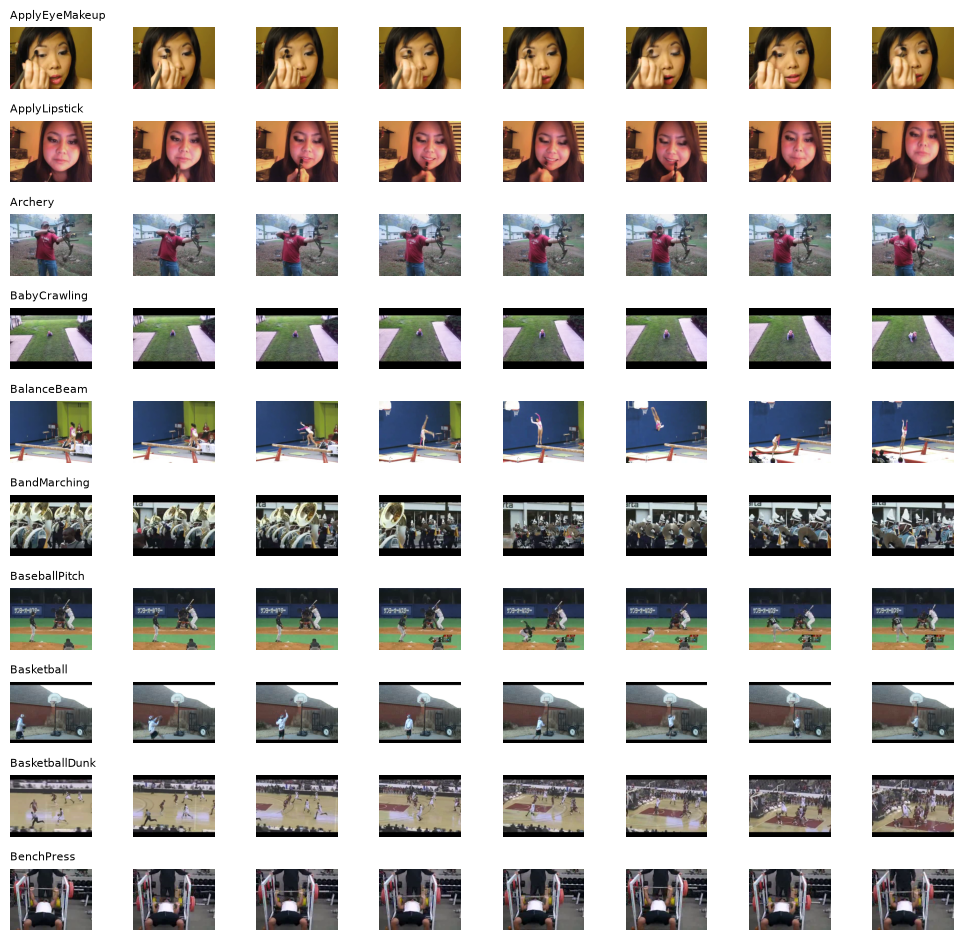

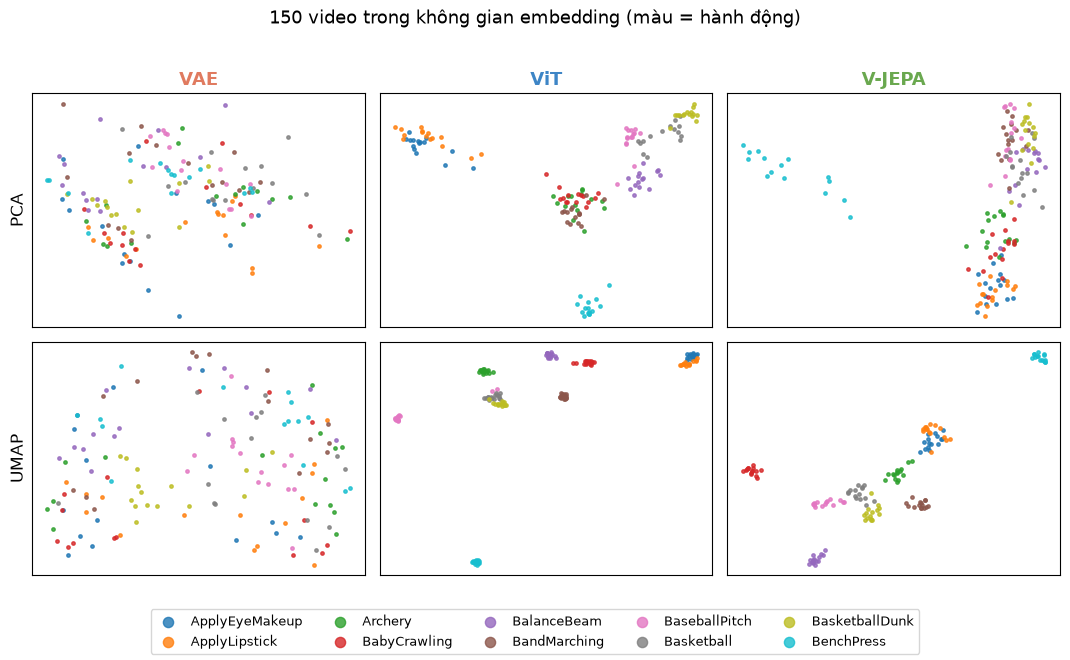

,Silhouette,k-NN acc,Linear probe acc
VAE,-0.090,0.333,0.533
ViT,0.408,0.927,0.980
V-JEPA,0.270,0.913,0.960


In [19]:
vrng = np.random.default_rng(SEED)
vpaths = []
for c in VCLASSES:
    ps = [p for p in videos if p.parent.name == c]
    vpaths += list(vrng.choice(ps, min(15, len(ps)), replace=False))
vlabels = np.array([VCLASSES.index(p.parent.name) for p in vpaths])
vgroups = np.array([f"{p.parent.name}_{p.stem.split('_')[-2]}" for p in vpaths])
clips = [read_clip(p) for p in vpaths]
print(len(clips), "video, mỗi video", clips[0].shape)

fig, axes = plt.subplots(len(VCLASSES), 8, figsize=(10, len(VCLASSES) * 0.95))
for c in range(len(VCLASSES)):
    clip = clips[np.where(vlabels == c)[0][0]]
    for j in range(8): axes[c, j].imshow(clip[j * 2]); axes[c, j].axis("off")
    axes[c, 0].set_title(VCLASSES[c], loc="left", fontsize=8)
plt.tight_layout(); plt.show()

def embed_clip(clip, m, frame_idx=None):
    fr = clip if frame_idx is None else clip[frame_idx]
    if m == "VAE": return S_vae(clip_to_tensor(fr, 256)).mean(0).numpy()      # trung bình các frame
    if m == "ViT": return S_vit(clip_to_tensor(fr, 224)).mean(0).numpy()      # trung bình các frame
    return S_vjepa(clip_to_tensor(clip, 256).unsqueeze(0))[0].numpy()        # cả clip

SV = cached("embeddings_videos", lambda: {m: np.stack([embed_clip(c, m) for c in clips]) for m in MODELS})
gcv = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(clips, vlabels, vgroups))
vmetrics = pd.DataFrame({m: evaluate(SV[m], vlabels, gcv) for m in MODELS}).T
scatter_grid(SV, vlabels, VCLASSES, MODELS, ["PCA", "UMAP"], "150 video trong không gian embedding (màu = hành động)")
vmetrics.round(3)

Nhận xét: ViT khoảng 98%, V-JEPA khoảng 96%, VAE khoảng 53%. ViT vẫn cao nhất vì 10 hành động này đoán được bằng bối cảnh (sân bóng rổ, phòng tập, bãi cỏ), chỉ cần nhìn từng frame tĩnh. Sự khác biệt của V-JEPA thể hiện ở các thí nghiệm về chuyển động trong phần 10 và 11.

## 10. So sánh 7 – Nhận diện vật thể chuyển động

Em tự tạo video: đặt một ảnh CIFAR (32×32) lên nền xám 64×64, rồi cho vật thể đứng yên ở giữa, hoặc chạy từ trái sang phải, hoặc từ phải sang trái trong 16 frame.

Em kiểm tra hai việc:
1. Khả năng nhận ra vật thể khi nó chạy: train linear probe trên video vật thể đứng yên (600 ảnh), rồi thử trên 200 ảnh khác ở 3 trạng thái.
2. Khả năng phân biệt hướng chạy: so sánh embedding của video chạy sang phải và chạy sang trái của cùng một ảnh (chuẩn hoá như phần 8, bằng 1 là không phân biệt được).

VAE và ViT lấy trung bình 8 frame. Em chọn 8 frame đối xứng để 2 hướng có cùng tập vị trí, so sánh cho công bằng.

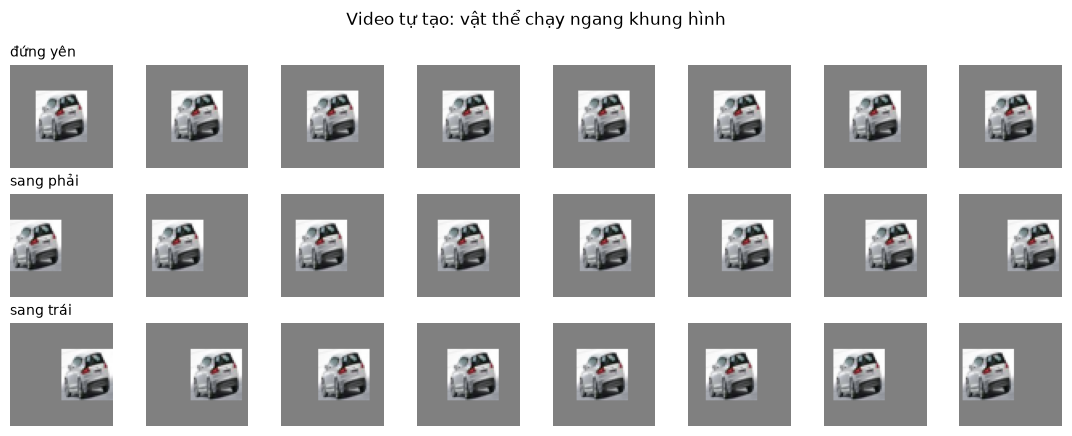

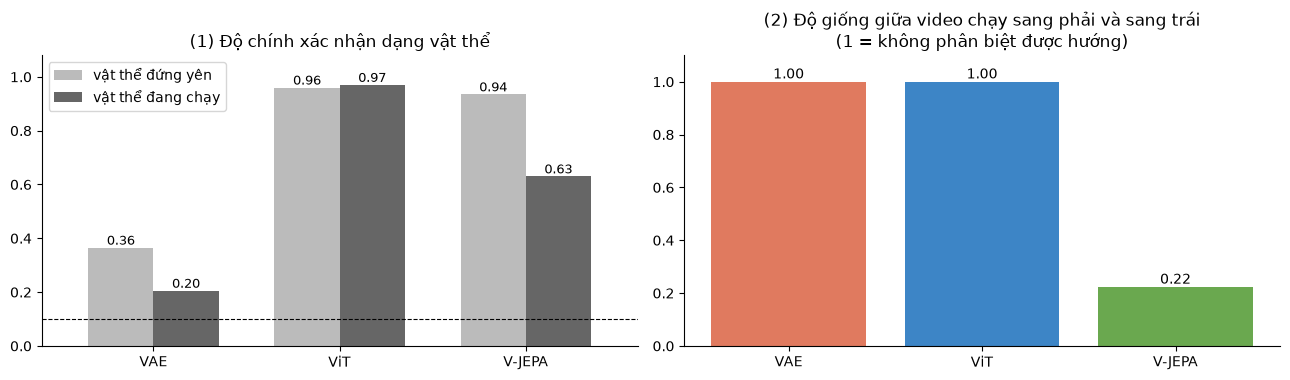

,vật thể đứng yên,vật thể đang chạy,giống nhau phải/trái
VAE,0.365,0.205,1.000
ViT,0.960,0.970,1.000
V-JEPA,0.935,0.630,0.223


In [20]:
def moving_clip(img, mode, T=16):
    obj = np.asarray(img, dtype=np.uint8)
    xs = {"đứng yên": np.full(T, 16), "sang phải": np.linspace(0, 32, T), "sang trái": np.linspace(32, 0, T)}[mode].round().astype(int)
    frames = np.full((T, 64, 64, 3), 128, np.uint8)
    for t, x in enumerate(xs): frames[t, 16:48, x:x + 32] = obj
    return frames

fig, axes = plt.subplots(3, 8, figsize=(11, 4.4))
for r, mode in enumerate(["đứng yên", "sang phải", "sang trái"]):
    clip = moving_clip(images[1 * N_PER_CLASS + 60], mode)
    for j in range(8): axes[r, j].imshow(clip[j * 2]); axes[r, j].axis("off")
    axes[r, 0].set_title(mode, loc="left", fontsize=10)
plt.suptitle("Video tự tạo: vật thể chạy ngang khung hình"); plt.tight_layout(); plt.show()

SYM = [0, 2, 4, 6, 9, 11, 13, 15]                      # 8 frame đối xứng
tr_idx = [c * N_PER_CLASS + j for c in range(10) for j in range(60)]
te_idx = [c * N_PER_CLASS + j for c in range(10) for j in range(60, 80)]
MODES = ["đứng yên", "sang phải", "sang trái"]

def moving_embeddings():
    out = {}
    for m in MODELS:
        out[f"{m}|train"] = np.stack([embed_clip(moving_clip(images[i], "đứng yên"), m, [0]) for i in tr_idx])
        for mode in MODES:
            fi = [0] if mode == "đứng yên" else SYM
            out[f"{m}|{mode}"] = np.stack([embed_clip(moving_clip(images[i], mode), m, fi) for i in te_idx])
    return out
ME = cached("moving_objects", moving_embeddings)

ytr, yte = labels[tr_idx], labels[te_idx]
acc, direction = {}, {}
for m in MODELS:
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1)).fit(ME[f"{m}|train"], ytr)
    acc[m] = {"vật thể đứng yên": clf.score(ME[f"{m}|đứng yên"], yte),
              "vật thể đang chạy": np.mean([clf.score(ME[f"{m}|{d}"], yte) for d in ["sang phải", "sang trái"]])}
    direction[m] = stability(ME[f"{m}|sang phải"], ME[f"{m}|sang trái"])
acc = pd.DataFrame(acc).T; direction = pd.Series(direction)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
acc.plot.bar(ax=axes[0], color=["#bbbbbb", "#666666"], rot=0, width=0.7)
for cont in axes[0].containers: axes[0].bar_label(cont, fmt="%.2f", fontsize=9)
axes[0].axhline(0.1, ls="--", c="k", lw=0.8); axes[0].set_ylim(0, 1.08); axes[0].set_title("(1) Độ chính xác nhận dạng vật thể")
bars = axes[1].bar(direction.index, direction.values, color=[COLORS[m] for m in direction.index])
axes[1].bar_label(bars, fmt="%.2f"); axes[1].set_ylim(0, 1.1)
axes[1].set_title("(2) Độ giống giữa video chạy sang phải và sang trái\n(1 = không phân biệt được hướng)")
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
pd.concat([acc, direction.rename("giống nhau phải/trái")], axis=1).round(3)

Nhận xét:
- ViT: nhận ra vật thể đang chạy tốt như khi đứng yên, nhưng video chạy sang phải và sang trái cho embedding giống hệt nhau (bằng 1). ViT xử lý từng frame riêng rồi lấy trung bình nên chỉ biết trong video có vật gì, không biết vật đi theo hướng nào.
- VAE: vốn nhận dạng kém, khi vật thể chạy còn kém hơn vì vị trí pixel thay đổi liên tục. Cũng không phân biệt được hướng (bằng 1) vì cũng lấy trung bình frame.
- V-JEPA: là mô hình duy nhất phân biệt được hướng chạy (độ giống chỉ khoảng 0.2). Nhưng độ chính xác khi vật thể chạy giảm khá nhiều so với khi đứng yên, do embedding của V-JEPA thay đổi theo chuyển động nên bộ phân loại học từ vật đứng yên bị lệch. V-JEPA mã hoá cả vật thể lẫn chuyển động trong cùng một vector.

## 11. So sánh 8 – Thứ tự thời gian trong video thật

Với 150 video thật, em tạo 3 phiên bản: phát ngược (frame 16 về 1), xáo trộn thứ tự frame, và đóng băng (lặp lại frame giữa 16 lần, không còn chuyển động). Sau đó so sánh embedding với video gốc (chuẩn hoá như phần 8).

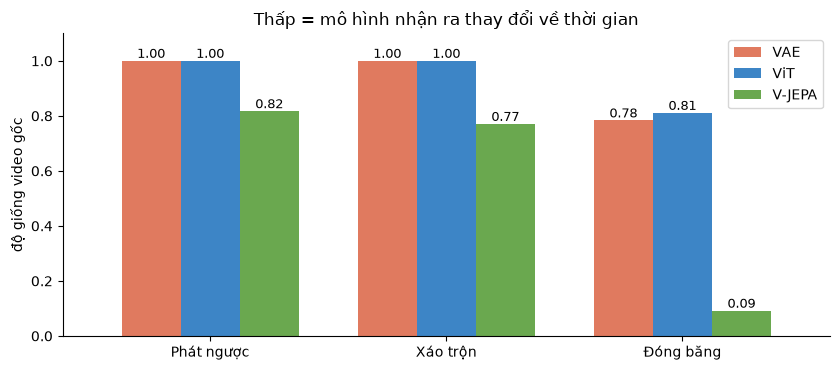

,Phát ngược,Xáo trộn,Đóng băng
VAE,1.000,1.000,0.783
ViT,1.000,1.000,0.811
V-JEPA,0.817,0.771,0.092


In [21]:
TESTS = {"Phát ngược": lambda c: c[::-1].copy(),
         "Xáo trộn":   lambda c: c[np.random.default_rng(SEED).permutation(len(c))],
         "Đóng băng":  lambda c: np.repeat(c[len(c) // 2][None], len(c), axis=0)}
def temporal_test():
    return {m: np.array([stability(SV[m], np.stack([embed_clip(f(c), m) for c in clips])) for f in TESTS.values()]) for m in MODELS}
temporal = pd.DataFrame(cached("temporal_videos", temporal_test), index=list(TESTS)).T

ax = temporal.T.plot.bar(figsize=(8.5, 3.8), color=[COLORS[m] for m in MODELS], width=0.75, rot=0)
for cont in ax.containers: ax.bar_label(cont, fmt="%.2f", fontsize=9)
ax.set_ylim(0, 1.1); ax.set_ylabel("độ giống video gốc"); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Thấp = mô hình nhận ra thay đổi về thời gian"); plt.tight_layout(); plt.show()
temporal.round(3)

Nhận xét:
- VAE và ViT bằng đúng 1.00 khi phát ngược hoặc xáo trộn, embedding không đổi, hai mô hình này không biết thứ tự thời gian.
- V-JEPA giảm còn khoảng 0.8, nhận ra được video bị đảo.
- Đóng băng: VAE và ViT vẫn khoảng 0.8 (frame giữa vẫn chứa cùng bối cảnh), còn V-JEPA xuống khoảng 0.09. Phần lớn thông tin trong embedding của V-JEPA là về chuyển động. Đây có thể là lý do trên ảnh tĩnh (giống video đóng băng) V-JEPA hơi thua ViT.

## 12. Bảng so sánh tổng hợp

In [22]:
best_k = {m: KS[int(np.argmax(kc[m]))] for m in ALL}
summary = pd.DataFrame({
    "Số chiều S":                       {m: S[m].shape[1] for m in ALL},
    "Ảnh – linear probe":               metrics["Linear probe acc"],
    "Ảnh – k-NN":                       metrics["k-NN acc"],
    "Silhouette theo lớp":              metrics["Silhouette"],
    "Số cụm tốt nhất (KMeans)":         pd.Series(best_k),
    "Silhouette KMeans k=30":           pd.Series({m: kc[m][KS.index(30)] for m in ALL}),
    "Số PC giữ 90% phương sai":         pd.Series(dim90),
    "CKA với Pixel":                    cka["Pixel"],
    "Ổn định khi đảo màu":              inv["Đảo màu"],
    "Video – linear probe":             vmetrics["Linear probe acc"],
    "Vật thể chạy – nhận dạng":         acc["vật thể đang chạy"],
    "Phải/trái giống nhau":             direction,
    "Video xáo frame – giống gốc":      temporal["Xáo trộn"],
    "Video đóng băng – giống gốc":      temporal["Đóng băng"],
}).reindex(ALL)
summary.T.style.format(lambda v: f"{v:.3f}" if isinstance(v, float) else v, na_rep="—")

,Pixel,VAE,ViT,V-JEPA
Số chiều S,3072.000,4096.000,768.000,1024.000
Ảnh – linear probe,0.268,0.300,0.956,0.946
Ảnh – k-NN,0.221,0.269,0.949,0.894
Silhouette theo lớp,-0.104,-0.041,0.219,0.196
Số cụm tốt nhất (KMeans),2.000,2.000,10.000,15.000
Silhouette KMeans k=30,0.047,0.042,0.163,0.191
Số PC giữ 90% phương sai,84.000,306.000,256.000,57.000
CKA với Pixel,1.000,0.903,0.142,0.132
Ổn định khi đảo màu,-0.955,-0.901,0.215,0.728
Video – linear probe,—,0.533,0.980,0.960


## Kết luận

### Điểm giống nhau
- Cả 3 đều là encoder đã huấn luyện sẵn, biến ảnh hoặc video thành một vector cố định và dùng được luôn mà không cần train lại.
- ViT và V-JEPA cùng là Transformer, cùng nắm được ngữ nghĩa (linear probe khoảng 95%, CKA với nhau khoảng 0.62), cùng hay nhầm trong nhóm động vật.
- VAE và ViT khi xử lý video bằng cách lấy trung bình frame thì đều không biết thứ tự thời gian và hướng chuyển động.

### Điểm khác nhau

| | VAE | ViT | V-JEPA |
|---|---|---|---|
| Cách học | tái tạo pixel, có ràng buộc KL | học có nhãn | đoán embedding phần bị che trong video |
| Hình dạng không gian | một khối cầu liền mạch, không có cụm | khoảng 10 cụm tách rời, đúng theo lớp | nhiều cụm nhỏ (vẫn tốt tới k=30), nối với nhau |
| Nhìn không gian trong ảnh | chi tiết từng điểm, giống pixel | chia mảng theo vật thể, attention vào vật thể chính | mượt, mỗi vùng mang cả thông tin lân cận |
| Thông tin chính | màu sắc, bố cục | loại vật thể | vật thể và chuyển động |
| Vẽ lại được ảnh | có | không | không |
| Bất biến | với ảnh xám | với lật ảnh | với đảo màu, cắt ảnh |
| Vật thể chuyển động | nhận dạng kém, không biết hướng | nhận dạng tốt, không biết hướng | biết hướng, nhưng nhận dạng bị ảnh hưởng |
| Thứ tự thời gian | không biết | không biết | biết |

### Điều em rút ra
1. Cách huấn luyện ảnh hưởng lớn tới không gian embedding. VAE học vẽ lại pixel nên không gian mịn nhưng chỉ chứa thông tin mức thấp. ViT học theo nhãn nên chia cụm đúng theo nhãn. V-JEPA học đoán embedding phần bị che nên có ngữ nghĩa kèm chuyển động.
2. Không cần nhãn vẫn học được ngữ nghĩa nếu mô hình dự đoán trong không gian embedding thay vì dự đoán pixel (ý tưởng của kiến trúc JEPA, Yann LeCun). Trong bài này V-JEPA gần bằng ViT, còn VAE thua xa.
3. Tuỳ việc mà chọn mô hình: sinh ảnh hoặc nén ảnh dùng VAE, phân loại hay tìm kiếm ảnh dùng ViT, hiểu video và chuyển động dùng V-JEPA.

### Hạn chế
- Ảnh CIFAR-10 chỉ 32×32, phải phóng to lên 224/256 nên khá mờ.
- ViT được train trên ImageNet có nhiều lớp trùng với CIFAR-10 nên có lợi thế. V-JEPA thì nhận ảnh tĩnh, không phải loại dữ liệu nó được train.
- Ba mô hình có kích thước khác nhau (V-JEPA 326M tham số, ViT 86M, VAE 84M).
- Bộ video nhỏ (150 video) và các hành động đoán được bằng bối cảnh. Nếu có thời gian em muốn thử thêm bộ Something-Something v2, nơi hành động chỉ phân biệt được qua chuyển động.